***LAB 04***

**DECISION TREE CLASSIFIER**

*Task 1: Load Dataset*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
iris = load_iris(as_frame=True)
data = iris.frame
data['species'] = data['target'].map(dict(enumerate(iris.target_names)))
print(data.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


Load dataset from CSV (alternative). Save the dataset as csv and read it back.

In [3]:
#save the dataset to csv
data.to_csv('iris.csv', index=False)

#load the dataset from csv (for your own file just change the file name/path)
data = pd.read_csv('iris.csv')
print(data.shape)

(150, 6)


*Task 2: Exploratory Data Analysis (EDA)*

In [4]:
#dataset information, shape and statistical summary
data.info()
print(data.shape)
print(data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB
(150, 6)
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
7

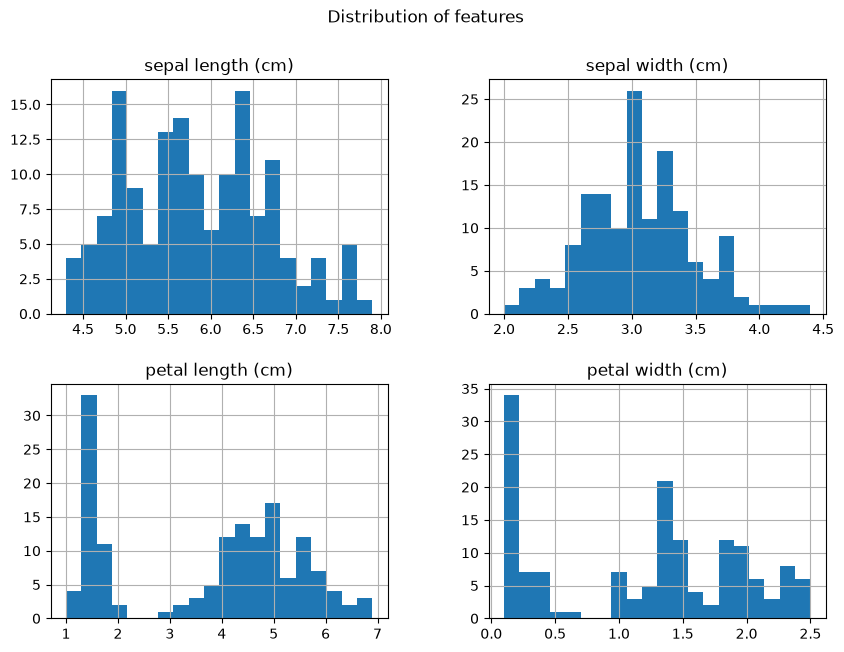

In [5]:
#distribution of features
data.drop(columns=['target','species']).hist(bins=20, figsize=(10,7))
plt.suptitle('Distribution of features')
plt.show()

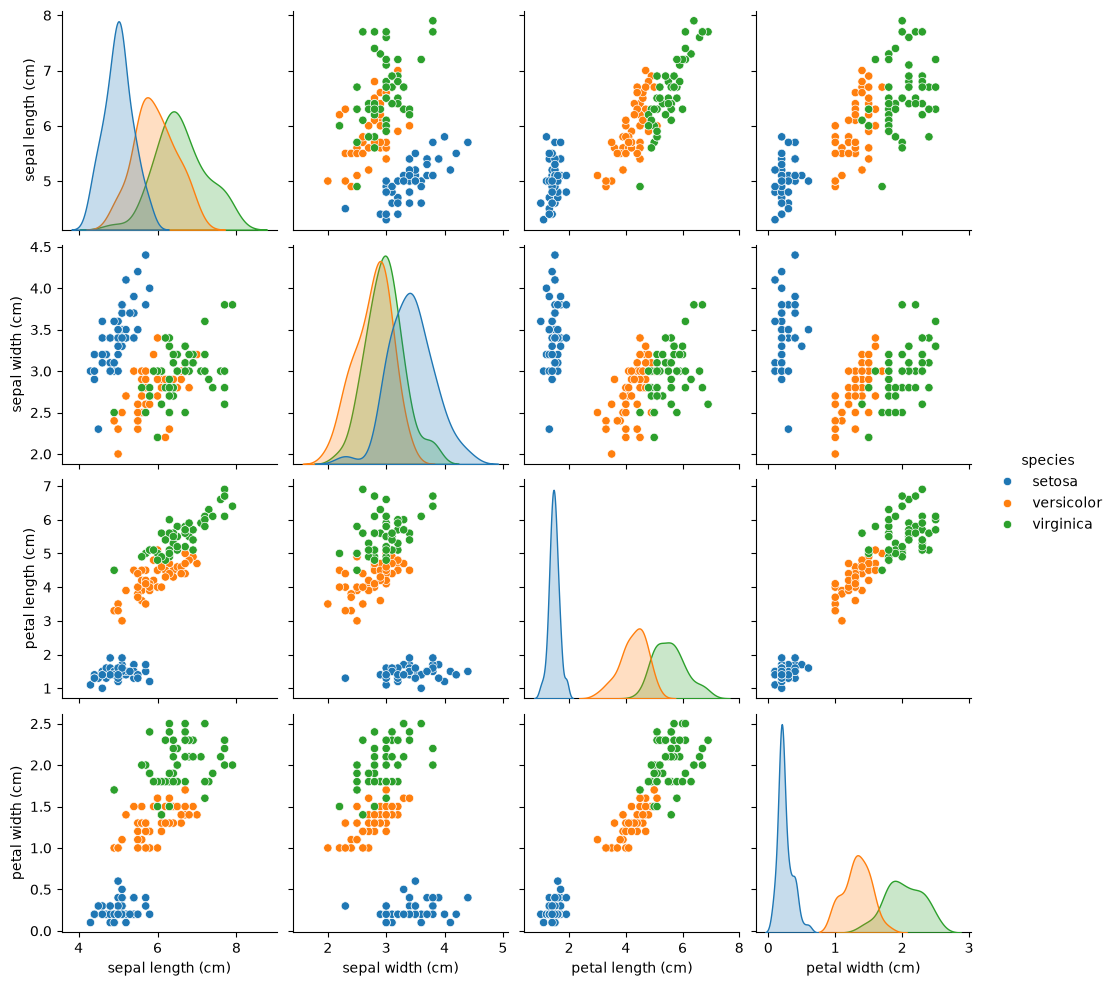

In [6]:
#pairplot
sns.pairplot(data.drop(columns='target'), hue='species')
plt.show()

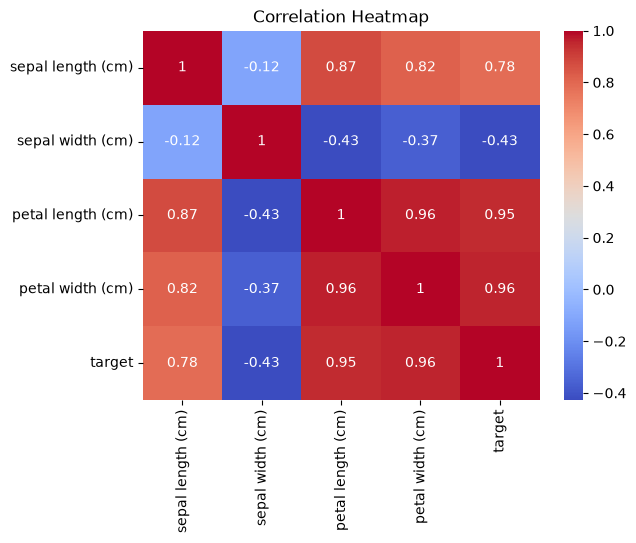

In [7]:
#correlation heatmap
sns.heatmap(data.drop(columns='species').corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Petal length and petal width are highly correlated with each other and with the target, so they are the best features to separate the species. In the pairplot setosa is clearly separate while versicolor and virginica overlap a little.

*Task 3: Data Preprocessing*

In [8]:
#features and labels
X = data.drop(columns=['target','species'])
y = data['target']

#70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(105, 4) (45, 4)


Decision trees do not need feature scaling, so no scaler is used here.

*Task 4: Build Decision Tree Classifier*

In [9]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

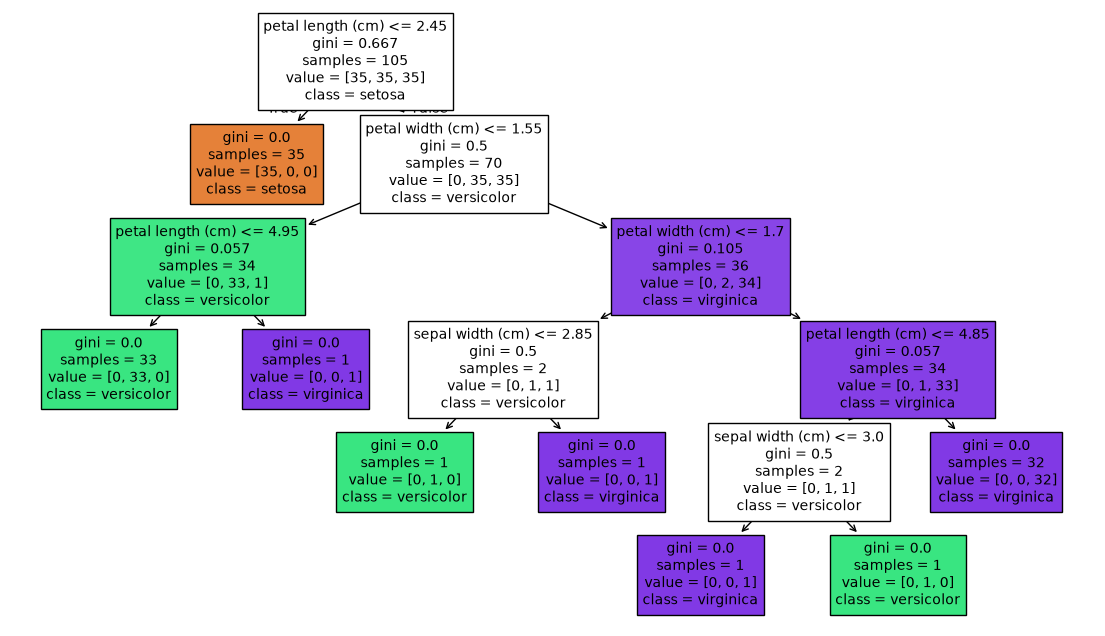

In [10]:
#visualize the tree
plt.figure(figsize=(14,8))
plot_tree(model, feature_names=X.columns, class_names=iris.target_names, filled=True)
plt.show()

*Task 5: Model Evaluation*

In [11]:
y_pred = model.predict(X_test)

print('Accuracy =', accuracy_score(y_test, y_pred))

Accuracy = 0.9333333333333333


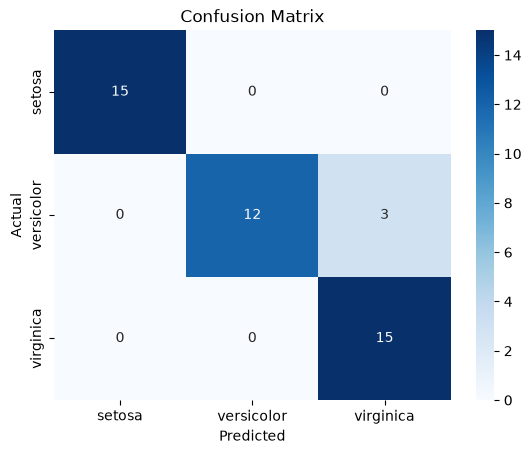

In [12]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [13]:
print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



*Task 6: Experimentation*

Gini vs Entropy

In [14]:
for crit in ['gini', 'entropy']:
    m = DecisionTreeClassifier(criterion=crit, random_state=42).fit(X_train, y_train)
    print(crit, '-> train acc =', m.score(X_train, y_train), ', test acc =', m.score(X_test, y_test))

gini -> train acc = 1.0 , test acc = 0.9333333333333333
entropy -> train acc = 1.0 , test acc = 0.8888888888888888


Effect of max_depth (overfitting vs underfitting)

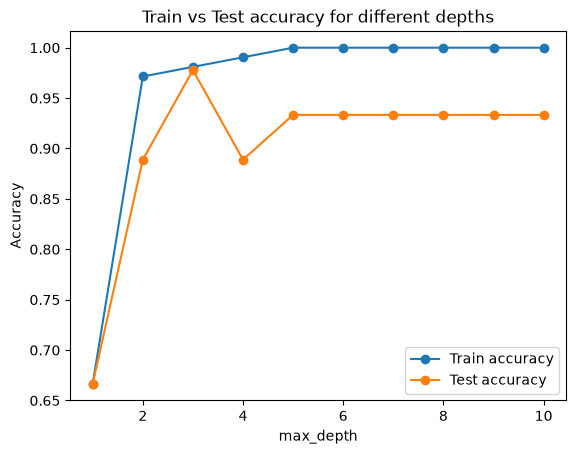

In [15]:
depths = range(1, 11)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(depths, train_acc, marker='o', label='Train accuracy')
plt.plot(depths, test_acc, marker='o', label='Test accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Train vs Test accuracy for different depths')
plt.legend()
plt.show()

Effect of min_samples_split

In [16]:
results = []
for s in [2, 5, 10, 20, 40]:
    m = DecisionTreeClassifier(min_samples_split=s, random_state=42).fit(X_train, y_train)
    results.append([s, m.score(X_train, y_train), m.score(X_test, y_test)])

print(pd.DataFrame(results, columns=['min_samples_split', 'Train acc', 'Test acc']).round(3))

   min_samples_split  Train acc  Test acc
0                  2      1.000     0.933
1                  5      0.981     0.933
2                 10      0.981     0.933
3                 20      0.981     0.933
4                 40      0.971     0.889


With max_depth = 1 the tree is too simple, so both train and test accuracy are low (underfitting). As the depth increases, train accuracy reaches almost 100% but test accuracy stops improving or even drops a little, which means the tree starts memorizing noise (overfitting).

Gini and entropy give almost the same results on this dataset. A small max_depth (like 3) or a larger min_samples_split (pre-pruning) gives a simpler tree that generalizes better.